In [1]:
import networkx as nx

import numpy as np
import matplotlib.pyplot as plt 
from math import comb, factorial
from itertools import combinations
from functools import partial

from typing import Union

from tabulate import tabulate
import pandas as pd

from scipy.linalg import sqrtm,eig


import perceval as pcvl
import exqalibur as xqlbr

from BSutils import *

In [2]:

# adj = np.array([
#   [0,1,1,1,1,0,0,1],
#   [1,0,1,0,1,1,0,0],
#   [1,1,0,1,0,1,0,0],
#   [1,0,1,0,1,0,1,0],
#   [1,1,0,1,0,0,0,0],
#   [0,1,1,0,0,0,0,0],
#   [0,0,0,1,0,0,0,0],
#   [1,0,0,0,0,0,0,0]
# ])


# # adj = np.array([
# #   [0,0,0,0,0,0,1,0,1,1,1,0],
# #   [0,0,1,0,0,1,0,0,0,1,0,1],
# #   [0,1,0,1,1,0,1,0,0,0,1,1],
# #   [0,0,1,0,1,1,1,0,1,1,1,1],
# #   [0,0,1,1,0,0,1,1,1,1,1,1],
# #   [0,1,0,1,0,0,1,1,0,1,1,0],
# #   [1,0,1,1,1,1,0,0,0,0,1,0],
# #   [0,0,0,0,1,1,0,0,0,1,0,1],
# #   [1,0,0,1,1,0,0,0,0,1,0,0],
# #   [1,1,0,1,1,1,0,1,1,0,1,0],
# #   [1,0,1,1,1,1,1,0,0,1,0,0],
# #   [0,1,1,1,1,0,0,1,0,0,0,0]
# # ])

# # adj = np.array([
# #   [0,0,1,1,0,1,1,1,1,0],
# #   [0,0,1,1,1,0,1,1,1,0],
# #   [1,1,0,1,0,0,0,0,1,1],
# #   [1,1,1,0,1,1,0,1,1,0],
# #   [0,1,0,1,0,1,0,0,0,1],
# #   [1,0,0,1,1,0,0,0,1,0],
# #   [1,1,0,0,0,0,0,0,0,0],
# #   [1,1,0,1,0,0,0,0,1,1],
# #   [1,1,1,1,0,1,0,1,0,1],
# #   [0,0,1,0,1,0,0,1,1,0]
# # ])


# # adj = np.array([
# #   [0,0,0,0,0,0,1,0,1,1,1,0],
# #   [0,0,1,0,0,1,0,0,0,1,0,1],
# #   [0,1,0,1,1,0,1,0,0,0,1,1],
# #   [0,0,1,0,1,1,1,0,1,1,1,1],
# #   [0,0,1,1,0,0,1,1,1,1,1,1],
# #   [0,1,0,1,0,0,1,1,0,1,1,0],
# #   [1,0,1,1,1,1,0,0,0,0,1,0],
# #   [0,0,0,0,1,1,0,0,0,1,0,1],
# #   [1,0,0,1,1,0,0,0,0,1,0,0],
# #   [1,1,0,1,1,1,0,1,1,0,1,0],
# #   [1,0,1,1,1,1,1,0,0,1,0,0],
# #   [0,1,1,1,1,0,0,1,0,0,0,0]
# # ])



# # adj = np.array([
# #   [0,1,0,0,1,1,1,0,1,1],
# #   [1,0,1,0,0,0,1,1,1,1],
# #   [0,1,0,1,0,1,0,1,1,1],
# #   [0,0,1,0,1,0,0,1,1,0],
# #   [1,0,0,1,0,1,0,1,0,1],
# #   [1,0,1,0,1,0,0,0,1,0],
# #   [1,1,0,0,0,0,0,0,1,1],
# #   [0,1,1,1,1,0,0,0,1,0],
# #   [1,1,1,1,0,1,1,1,0,0],
# #   [1,1,1,0,1,0,1,0,0,0]
# # ])

# # adj = np.array([
# #   [0,1,1,1,0,0,0,0,0,0,0,0],
# #   [1,0,1,1,1,0,0,0,1,0,0,0],
# #   [1,1,0,1,0,0,0,0,1,0,0,1],
# #   [1,1,1,0,0,0,0,0,0,0,0,0],
# #   [0,1,0,0,0,0,0,0,1,0,0,0],
# #   [0,0,0,0,0,0,0,0,0,0,0,1],
# #   [0,0,0,0,0,0,0,1,1,1,1,1],
# #   [0,0,0,0,0,0,1,0,1,1,1,1],
# #   [0,1,1,0,1,0,1,1,0,1,1,1],
# #   [0,0,0,0,0,0,1,1,1,0,1,1],
# #   [0,0,0,0,0,0,1,1,1,1,0,1],
# #   [0,0,1,0,0,1,1,1,1,1,1,0]
# # ])


# # new

# # adj = np.array([
# #   [0,1,1,1,1,1,0,0,0,0,0,0],
# #   [1,0,1,1,1,1,0,0,1,0,0,0],
# #   [1,1,0,1,0,0,0,0,1,0,0,1],
# #   [1,1,1,0,0,0,0,0,0,0,0,0],
# #   [1,1,0,0,0,1,0,0,0,0,0,0],
# #   [1,1,0,0,1,0,0,0,0,0,0,0],
# #   [0,0,0,0,0,0,0,1,1,1,1,1],
# #   [0,0,0,0,0,0,1,0,1,1,1,1],
# #   [0,1,1,0,0,0,1,1,0,1,1,1],
# #   [0,0,0,0,0,0,1,1,1,0,1,1],
# #   [0,0,0,0,0,0,1,1,1,1,0,1],
# #   [0,0,1,0,0,0,1,1,1,1,1,0]
# # ])


# adj = np.array([
#   [0,1,1,1,0,0,1,0,0,0],
#   [1,0,1,0,1,1,0,0,1,1],
#   [1,1,0,0,0,0,1,0,0,1],
#   [1,0,0,0,1,0,1,1,1,1],
#   [0,1,0,1,0,1,0,1,0,1],
#   [0,1,0,0,1,0,1,0,0,1],
#   [1,0,1,1,0,1,0,1,1,0],
#   [0,0,0,1,1,0,1,0,1,1],
#   [0,1,0,1,0,0,1,1,0,1],
#   [0,1,1,1,1,1,0,1,1,0]
# ])

# np.where(adj!=adj.transpose())

# G = nx.Graph()
# for i in range(len(adj)):
#    G.add_node(i)
   
# for i in range(len(adj)): 
#  for j in range(len(adj)): 
#    if adj[i][j] == 1: 
#       G.add_edge(i,j) 







### Graph definition

In [3]:
nodes = 12
parameter = 0.5

In [4]:

G = nx.erdos_renyi_graph(nodes,p=parameter)


pos = nx.spring_layout(G, seed=42)

adj = nx.adjacency_matrix(G).toarray()

print(adj)



[[0 0 0 0 0 1 1 1 1 1 1 0]
 [0 0 1 1 0 1 1 1 0 0 0 0]
 [0 1 0 0 0 0 1 0 1 0 0 0]
 [0 1 0 0 0 1 1 1 0 0 1 0]
 [0 0 0 0 0 1 1 0 1 0 1 1]
 [1 1 0 1 1 0 1 1 0 0 1 0]
 [1 1 1 1 1 1 0 1 0 1 1 0]
 [1 1 0 1 0 1 1 0 0 0 0 0]
 [1 0 1 0 1 0 0 0 0 1 0 1]
 [1 0 0 0 0 0 1 0 1 0 1 0]
 [1 0 0 1 1 1 1 0 0 1 0 0]
 [0 0 0 0 1 0 0 0 1 0 0 0]]


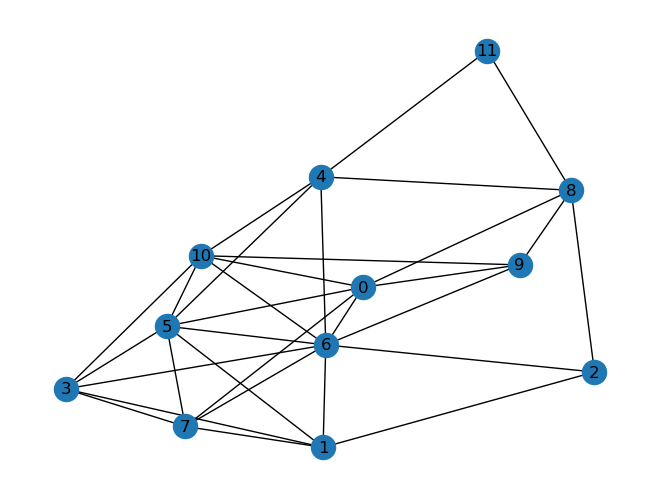

In [5]:

nx.draw( G , with_labels = True,pos=pos) 
plt.show()

### Boson Sampling results

In [6]:
n = nodes
k = n//2
# k = 5
print(n,"nodes")
print(comb(n,k), "subgraphs of size", k)




12 nodes
924 subgraphs of size 6


In [ ]:

select_out = np.array(
    [
        [1 if i in comb else 0 for i in range(n)]
        for comb in combinations(np.arange(n), k)
    ]
    )
# print(select_out)
#For multiple application of U_A

# vals,_ = eig(adj)
# print(vals[0])
# adjbis = adj/vals[0]
# D = sqrtm(np.eye(len(adj)) - adjbis*adjbis.conjugate())
# res = [(o,np.abs(superposition_perm(adjbis@adjbis+D*D,o)[0])) for o in select_out ]


res = [(o,np.abs(superposition_perm(adj,o)[0])) for o in select_out ]

res.sort(key=lambda x: x[1])
print("Total value of permanents (without V matrix)", res[-1])


res_pure = [(o,np.abs(perm_estimation_graph(adj,o))) for o in select_out ]
# offdiag_res = [(o,np.abs(perm_estimation_graph(G,o))) for o in select_out ]

res_pure.sort(key=lambda x: x[1])
print("Pure value of permanent ",res_pure[-1])



[[1 1 1 ... 0 0 0]
 [1 1 1 ... 0 0 0]
 [1 1 1 ... 0 0 0]
 ...
 [0 0 0 ... 1 1 1]
 [0 0 0 ... 1 1 1]
 [0 0 0 ... 1 1 1]]
Total value of permanents (without V matrix) (array([1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0]), 14296.0)
Pure value of permanent  (array([1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0]), 116.0)


Pure permanent values


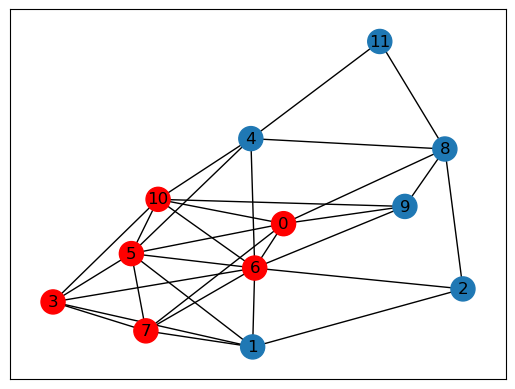

In [9]:

colours = ['#1f78b4' if i==0 else 'red' for i in res_pure[-1][0]]

nx.draw_networkx(G, node_color=colours,pos=pos)
print("Pure permanent values")
plt.show()

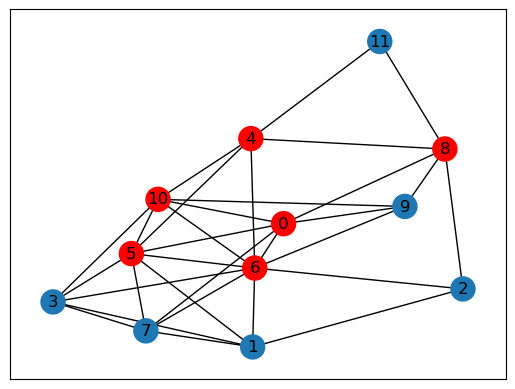

In [10]:

colours = ['#1f78b4' if i==0 else 'red' for i in res[-1][0]]

nx.draw_networkx(G, node_color=colours,pos=pos)
plt.show()

In [11]:
header = ["state","Permanent","Rectangular Permanent","density"]

fullres = [("".join(str(i) for i in state), val, np.abs(superposition_perm(adj,state)[0]), np.round(density(G,state),3)) 
           for state,val in res_pure]

results = pd.DataFrame(fullres,columns = header)

In [12]:

results.sort_values(by = "Permanent", ascending=False,inplace=True)

print(tabulate(results,headers=header ,tablefmt="pretty",showindex=False))
    

    

+--------------+-----------+-----------------------+---------+
|    state     | Permanent | Rectangular Permanent | density |
+--------------+-----------+-----------------------+---------+
| 100101110010 |   116.0   |        9426.0         |  0.867  |
| 010101110010 |   93.0    |        6970.0         |  0.867  |
| 110101110000 |   93.0    |        7748.0         |  0.867  |
| 110101100010 |   57.0    |        10237.0        |   0.8   |
| 000111110010 |   57.0    |        9071.0         |   0.8   |
| 010111100010 |   57.0    |        10063.0        |   0.8   |
| 100001110110 |   57.0    |        8242.0         |   0.8   |
| 100011100110 |   57.0    |        9150.0         |   0.8   |
| 100011110010 |   57.0    |        12052.0        |   0.8   |
| 100101100110 |   57.0    |        8234.0         |   0.8   |
| 110001110010 |   57.0    |        10167.0        |   0.8   |
| 100010101110 |   53.0    |        7218.0         |  0.733  |
| 010111110000 |   40.0    |        7241.0         |   

In [13]:

results.sort_values(by = "Rectangular Permanent", ascending=False,inplace=True)

print(tabulate(results,headers=header ,tablefmt="pretty",showindex=False))
    

+--------------+-----------+-----------------------+---------+
|    state     | Permanent | Rectangular Permanent | density |
+--------------+-----------+-----------------------+---------+
| 100011101010 |   36.0    |        14296.0        |  0.733  |
| 100101101010 |    9.0    |        13218.0        |  0.667  |
| 110001101010 |    4.0    |        12946.0        |   0.6   |
| 110011100010 |   16.0    |        12727.0        |  0.733  |
| 100001111010 |    4.0    |        12686.0        |  0.667  |
| 100011111000 |   25.0    |        12554.0        |  0.667  |
| 110011101000 |   16.0    |        12407.0        |   0.6   |
| 100011110010 |   57.0    |        12052.0        |   0.8   |
| 000111101010 |    9.0    |        11997.0        |  0.667  |
| 010011101010 |    4.0    |        11773.0        |   0.6   |
| 100111101000 |   16.0    |        11705.0        |   0.6   |
| 100111100010 |   36.0    |        11648.0        |   0.8   |
| 110001111000 |    9.0    |        11253.0        |  0

In [14]:
np.array([i for i in "010101"],dtype=int)

array([0, 1, 0, 1, 0, 1])

### Bobkov bound

#### sanity check

In [15]:
# # Works like a charm
# # https://github.com/theochem/matrix-permanent/

# import sys
# sys.path.append("path_to_matrix-permanent")
# # sys.path.append("../matrix-permanent_github/matrix_permanent")

# import permanent
# state = [1, 1, 1 ,1 ,0 ,0 ,0 ,0]
# submatrix = adj[np.where(state)[0],:]
# print(submatrix)
# print(permanent.ryser(submatrix))

In [16]:
def check_criteria(in_state: Union[str,np.array],adj, k=n//2):

    if(type(in_state)==str):
        in_state = np.array([i for i in in_state],dtype=int)

    n = len(adj)
    # print(len( adj[:,np.where(in_state)[0]]))

    prodzk = np.prod(np.mean(adj[:,np.where(in_state)[0]],axis=0))

    centers = factorial(n)/factorial(n-k)*prodzk
    boundary = 16 * k/n * factorial(n)/factorial(n-k)
    
    return np.round(centers,1) #, boundary


# np.prod(np.mean(adj[:,n//2:],axis=0))

In [17]:
results['state'][0]
check_criteria(results['state'][0],adj)

3509.1

In [18]:
results['centers_zk'] = results['state'].apply(partial(check_criteria,adj=adj))

In [19]:
boundary = 16 * k/n * factorial(n)/factorial(k)
    
print("boundary : ",boundary)

# print(results)
# results.sort_values(by = "messy sum", ascending=False,inplace=True)
print(tabulate(results,headers=header+["centers_zk"] ,tablefmt="pretty",showindex=False))
    

boundary :  5322240.0
+--------------+-----------+-----------------------+---------+------------+
|    state     | Permanent | Rectangular Permanent | density | centers_zk |
+--------------+-----------+-----------------------+---------+------------+
| 100011101010 |   36.0    |        14296.0        |  0.733  |  12632.8   |
| 100101101010 |    9.0    |        13218.0        |  0.667  |  12632.8   |
| 110001101010 |    4.0    |        12946.0        |   0.6   |  12632.8   |
| 110011100010 |   16.0    |        12727.0        |  0.733  |  12632.8   |
| 100001111010 |    4.0    |        12686.0        |  0.667  |  12632.8   |
| 100011111000 |   25.0    |        12554.0        |  0.667  |  10527.3   |
| 110011101000 |   16.0    |        12407.0        |   0.6   |  10527.3   |
| 100011110010 |   57.0    |        12052.0        |   0.8   |  12632.8   |
| 000111101010 |    9.0    |        11997.0        |  0.667  |  10527.3   |
| 010011101010 |    4.0    |        11773.0        |   0.6   |  10